# 1 · Diffusion from a single region — corrected

Corrected version of [`original/notebooks/01-diffusion-single-region.ipynb`](../../original/notebooks/01-diffusion-single-region.ipynb). The original is kept unchanged as the record of the summer-school work.

**Model** — pure diffusion of the tumour cell density $n$:

$$\frac{\partial n}{\partial t} = D\,\nabla^2 n$$

**What changed from the original**

- **Diffusion coefficient.** The original update was `delta_t * (D * (delta_t / delta_x) * (...))`, an extra factor of `delta_t` and `delta_x` instead of `delta_x**2`, so diffusion ran at an effective $D = 0.1$ instead of $D = 1$. It now uses `D * delta_t / delta_x**2`.
- **No growth term.** The original also contained a logistic growth term, although this model is described as diffusion only. It is removed.
- **Speed.** The three nested Python loops are replaced by NumPy array operations (same 5-point stencil, same periodic boundaries).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Parameters (same as the original)
l = 100          # grid size (l x l cells)
A = 0.1          # peak density of the initial Gaussian
σ = 10           # width of the initial tumour
delta_t = 0.1
delta_x = 1
D = 1
num_steps = 60

# The explicit scheme is only stable if D*dt/dx^2 <= 0.25 (2D, 5-point stencil)
assert D * delta_t / delta_x**2 <= 0.25, "unstable: reduce delta_t"

In [3]:
def laplacian(n):
    """5-point Laplacian. np.roll wraps around the edges, giving the same
    periodic boundaries as the original notebook."""
    return (np.roll(n, 1, axis=0) + np.roll(n, -1, axis=0)
            + np.roll(n, 1, axis=1) + np.roll(n, -1, axis=1) - 4 * n) / delta_x**2

In [4]:
i, j = np.meshgrid(np.arange(l), np.arange(l), indexing="ij")
n = A * np.exp(-((i - l/2)**2 + (j - l/2)**2) / (2 * σ**2))
n_initial = n.copy()

In [5]:
frames = {0: n.copy()}
for step in range(1, num_steps + 1):
    n = n + delta_t * D * laplacian(n)
    if step in (20, 40, 60):
        frames[step] = n.copy()

# Sanity check: with periodic boundaries, diffusion only moves cells around,
# so the total must stay the same.
print(f"total density: start {n_initial.sum():.6f}, end {n.sum():.6f}")

total density: start 62.831779, end 62.831779


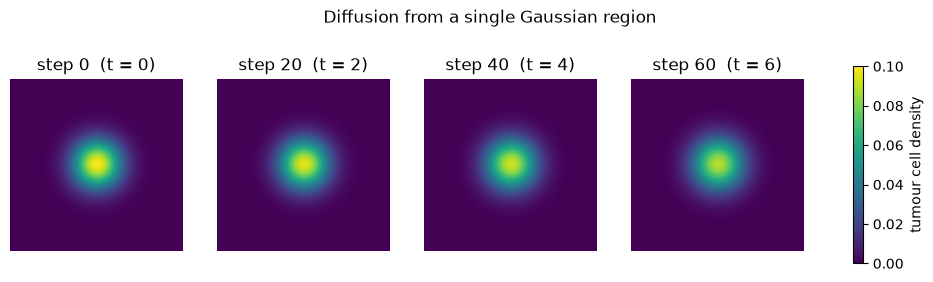

In [6]:
fig, axes = plt.subplots(int(np.ceil(len(frames) / 4)), 4, figsize=(3.2 * 4, 3.2 * int(np.ceil(len(frames) / 4))), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, (step, frame) in zip(axes.flat, frames.items()):
    im = ax.imshow(frame, origin="lower", cmap="viridis", vmin=0, vmax=A)
    ax.set_title(f"step {step}  (t = {step * delta_t:g})")
fig.colorbar(im, ax=axes, shrink=0.8, label="tumour cell density")
fig.suptitle("Diffusion from a single Gaussian region")
plt.show()

**Reading the result.** The tumour spreads symmetrically and its peak drops while the total stays constant. This is what pure diffusion should do.